# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [16]:
# importar librerías

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [17]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv') #completa el código

In [18]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [19]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [20]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [21]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [22]:
# inspección de plans con .info()
plans.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [23]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [24]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [25]:
# cantidad de nulos para users
print("Cantidad de valores nulos")
print(users.isnull().sum())
print("\nProporción de valores nulos (%)")
print(users.isnull().mean() * 100)

Cantidad de valores nulos
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos (%)
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [26]:
# cantidad de nulos para usage
print("Cantidad de valores nulos")
print(usage.isnull().sum())

print("\nProporción de valores nulos (%)")
print(usage.isnull().mean() * 100)

Cantidad de valores nulos
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos (%)
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

city (11.725 %): Presenta 469 valores nulos. Se recomienda investigar la información faltante y, si no puede recuperarse, clasificarla como "Desconocido" para conservar los registros.

churn_date (88.350 %): Presenta 3,534 valores nulos. Estos podrían representar clientes activos que aún no han cancelado su servicio. Se recomienda conservarlos y verificar su significado antes de realizar modificaciones.

Otras columnas: No presentan valores nulos y no requieren tratamiento.

date (0.125 %): Presenta 50 valores nulos. Se recomienda investigar estos registros y considerar excluirlos únicamente de los análisis temporales si no es posible recuperar las fechas.

duration (55.190 %): Presenta 22,076 valores nulos. Se recomienda verificar si corresponden a registros de mensajes, donde la duración no aplica, antes de decidir cualquier imputación.

length (44.740 %): Presenta 17,896 valores nulos. Se recomienda comprobar si corresponden a llamadas, donde la longitud del mensaje no aplica.


💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).

* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Dataset users:

city: 469 nulos (11.725 %).

churn_date: 3,534 nulos (88.350 %).

- Dataset usage:

date: 50 nulos (0.125 %).

duration: 22,076 nulos (55.190 %).

length: 17,896 nulos (44.740 %).

- Indica qué harías: ¿imputar, eliminar, ignorar?
  
city: Imputar con "Desconocido" para conservar los registros sin inventar ciudades.

churn_date: Mantener los nulos, ya que podrían representar clientes que todavía tienen el servicio activo.

date: Conservar inicialmente e investigar; excluir los registros sin fecha únicamente de análisis temporales si no se puede recuperar.

duration: Mantener los nulos hasta verificar si corresponden a mensajes, donde la duración no aplica.

length: Mantener los nulos hasta verificar si corresponden a llamadas, donde la longitud del mensaje no aplica.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [27]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Los identificadores van desde 10,000 hasta 13,999. No se observan valores inválidos evidentes . Sin embargo, todavía debemos verificar si existen identificadores duplicados.

- La columna `age` ...

 Mínimo: -999 → es un valor inválido y probablemente un sentinel. El valor -999 está afectando las estadísticas. Por ejemplo, hace que el promedio disminuya y aumenta artificialmente la desviación estándar.
Promedio: 33.74 años.
Mediana: 47 años.
Desviación estándar: 123.23, extremadamente alta para edades humanas.

 Se identificó un posible sentinel de -999, que representa una edad imposible. Este valor afecta el promedio (33.74) y la desviación estándar (123.23), generando estadísticas distorsionadas. Se recomienda investigar su frecuencia y reemplazarlo por NaN durante la limpieza.

In [28]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...
- id: contiene identificadores entre 1 y 40,000.
- user_id: contiene identificadores entre 10,000 y 13,999, coherentes con el rango observado en users.
No se encontro valores inválidos evidentes en estas columnas. Sin embargo, se debe comprobar que id no tenga duplicados y que los usuarios existan en el dataset users.

en la columna duration La mayoría de las llamadas parecen tener duraciones relativamente cortas, pero existen algunas mucho más largas.
Una llamada de 120 minutos no necesariamente es un error. Podría ser un cliente que realiza llamadas prolongadas.

en la columna length hay un resultdo de 1,490 caracteres.
Es considerablemente superior a la mediana, por lo que podría representar un comportamiento atípico, aunque no necesariamente un dato inválido.

In [29]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print("Columna:", columna)
    print(users[columna].value_counts(dropna=False))
    print("-------------------------")

Columna: city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
-------------------------
Columna: plan
Basico     2595
Premium    1405
Name: plan, dtype: int64
-------------------------


La columna city: Se identificaron 469 valores nulos (11.725%) y 96 registros con el sentinel "?" (2.4%). En total, el 14.125% de los clientes no tiene una ciudad identificable. Se recomienda reemplazar "?" por NaN y conservar los registros para no perder información de los clientes. Posteriormente, se puede utilizar la categoría "Desconocida" para el análisis por ciudad.

La columna plan: Se identificaron dos categorías: Basico (2,595 registros) y Premium (1,405 registros). No se encontraron valores faltantes ni sentinels evidentes. Se recomienda verificar que ambas categorías coincidan con el catálogo de planes.

In [30]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...
- Solo existen dos categorías: text y call.
- No hay valores nulos en type.
- No se observan sentinels ni categorías inválidas.
Por lo tanto, la columna type no necesita limpieza por valores inválidos, según los resultados obtenidos.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
users['age']: Se identificó el sentinel -999, que representa una edad imposible y distorsiona el promedio y la desviación estándar.

users['city']: Se encontraron 96 registros con el valor "?" (2.4%), además de 469 valores nulos (11.725%).

usage['duration']: Se encontró un valor máximo de 120 minutos, que podría representar un comportamiento atípico.

usage['length']: Se identificó un valor máximo de 1,490 caracteres, considerablemente superior a la mediana de 50.

users['plan'] y usage['type']: No se encontraron sentinels ni valores inválidos evidentes.

- ¿Qué acción tomarías?

Se identificaron sentinels en las columnas age y city, además de posibles valores atípicos en duration y length. Se recomienda corregir los sentinels confirmados y analizar los valores extremos antes de realizar modificaciones, para garantizar la calidad de los datos.

Edad: Reemplazar -999 por NaN para evitar distorsiones estadísticas.

Ciudad: Convertir "?" en NaN y conservar los registros para no perder información de los clientes.

Duración y longitud: Investigar los valores extremos antes de eliminarlos, ya que podrían representar comportamientos reales.

Valores nulos en usage: Verificar su relación con el tipo de actividad (call o text) antes de imputarlos.

Plan y tipo: Conservar las categorías actuales y validar los planes contra el catálogo oficial.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [31]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(
    users['reg_date'],
    errors='coerce'
)# completa el código

In [32]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(
    usage['date'],
    errors='coerce'
)# completa el código

In [33]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

La columna reg_date: Se identificaron registros correspondientes a los años 2022, 2023, 2024 y 2026. Los primeros tres años son válidos, ya que el proyecto contempla información hasta 2024. Sin embargo, se encontraron 40 registros (1%) correspondientes a 2026, los cuales están fuera del período esperado.

Acción recomendada: Investigar las 40 fechas inconsistentes y, si no es posible corregirlas con información confiable, reemplazarlas por NaT durante la limpieza, conservando los demás datos de los clientes.


In [34]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

La columna date: Se identificaron 39,950 registros (99.875%) correspondientes al año 2024, lo cual es consistente con el período del proyecto. También se encontraron 50 registros (0.125%) con fechas faltantes (NaT). No se identificaron años fuera de rango.

Acción recomendada: Investigar los 50 registros con fechas faltantes y, si no es posible recuperar las fechas originales, mantenerlos como NaT. Se recomienda excluirlos únicamente de los análisis que requieran información temporal, conservándolos para otros análisis de consumo.



✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

users['reg_date']: Se identificaron 40 registros (1%) correspondientes al año 2026, los cuales están fuera del período establecido, ya que los datos del proyecto llegan hasta 2024. Los registros de 2022, 2023 y 2024 son válidos.

usage['date']: Se encontraron 39,950 registros (99.875%) correspondientes a 2024 y 50 registros (0.125%) con fechas faltantes o inválidas (NaT). No se identificaron años fuera de rango.

- ¿Qué harías con ellas?

reg_date: Investigar las 40 fechas de 2026 para determinar si son errores de registro. Si no es posible corregirlas con información confiable, reemplazarlas por NaT, conservando los demás datos de los clientes.

date: Mantener los 50 registros con fechas faltantes como NaT si no es posible recuperar la información original. Excluirlos únicamente de los análisis temporales que requieran fechas válidas.

Validación: Estandarizar ambas columnas al formato datetime y comprobar que las fechas utilizadas en el análisis sean coherentes con el período del proyecto.

Conclusión: Se identificaron 90 registros con problemas de fechas entre ambos datasets. Es necesario tratar estas inconsistencias antes del análisis estadístico para evitar resultados incorrectos, sin eliminar información útil innecesariamente.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [35]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()

users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [36]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [37]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [38]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type')['duration'].apply(
    lambda x: x.isna().mean() * 100
))

type
call     0.000000
text    99.927576
Name: duration, dtype: float64


In [39]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')['length'].apply(
    lambda x: x.isna().mean() * 100
))

type
call    99.932991
text     0.000000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Al analizar los valores nulos según la columna type, se identificó que su ausencia está relacionada con el tipo de servicio utilizado.

duration: El 99.93% de los mensajes presenta valores nulos, mientras que las llamadas tienen un 0% de valores faltantes.

length: El 99.93% de las llamadas presenta valores nulos, mientras que los mensajes tienen un 0% de valores faltantes.

Conclusión: Los resultados son consistentes con un mecanismo MAR (Missing At Random), condicionado por la variable observada type. Más específicamente, la mayoría de estos nulos corresponde a campos que no aplican según el servicio.

Acción recomendada: Mantener los valores nulos sin imputarlos, ya que reemplazarlos por cero, la media o la mediana podría distorsionar el análisis. Para los análisis estadísticos, utilizar duration únicamente en llamadas y length únicamente en mensajes.

También se recomienda investigar el pequeño porcentaje de registros que presenta valores en campos que normalmente no corresponden a su tipo de servicio.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [40]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [41]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [42]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(
    usage_agg,
    on="user_id",
    how="left"
)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [43]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

user_profile[columnas_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [44]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

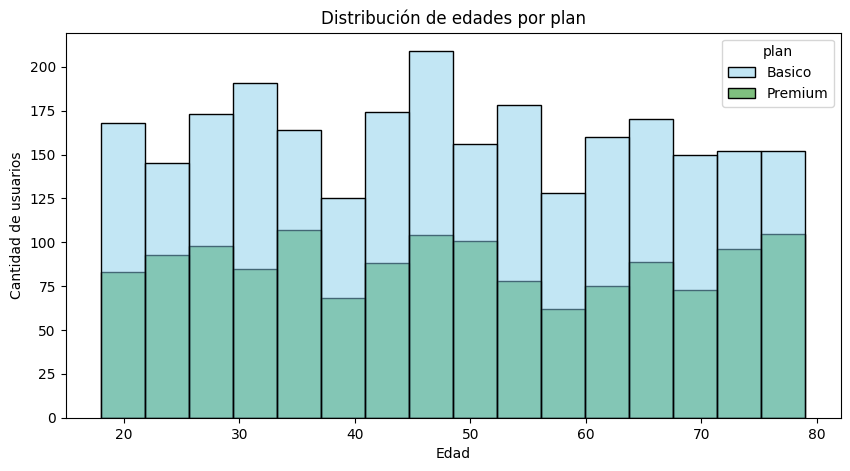

In [55]:
# Histograma para visualizar la edad (age)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    hue_order=['Basico', 'Premium'],
    bins=16,
    palette=['skyblue', 'green']
    
)

plt.title('Distribución de edades por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución ...

- La distribución de edades muestra presencia de clientes de diferentes grupos etarios tanto en el plan Básico como en el Premium. El plan Básico presenta una mayor cantidad de usuarios, lo cual es consistente con su mayor participación en la base de clientes (64.88%).

No se observa una concentración de edades claramente diferenciada entre ambos planes en este gráfico. Para determinar si existe una relación entre la edad y el tipo de plan contratado, sería recomendable comparar las distribuciones porcentuales y las edades promedio de cada segmento.

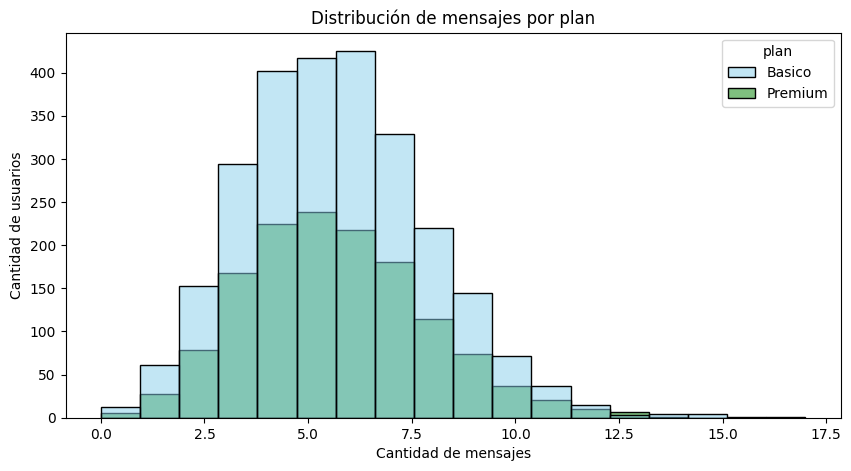

In [56]:
# Histograma para visualizar la cant_mensajes

# Histograma para visualizar cant_mensajes

plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    hue_order=['Basico', 'Premium'],
    palette=['skyblue', 'green'],
    bins=18
)

plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()




💡Insights: 
- ....
- La distribución de mensajes presenta una concentración principalmente entre 4 y 7 mensajes por usuario, con una forma aproximadamente de campana y un ligero sesgo hacia la derecha.

Ambos planes muestran patrones de consumo visualmente similares. Aunque el plan Básico registra una mayor cantidad de usuarios, esto se relaciona con su mayor participación en la base de clientes (64.88%).

Se identifican algunos usuarios con consumos superiores a 12 mensajes, que podrían representar valores atípicos y requieren una evaluación estadística adicional.

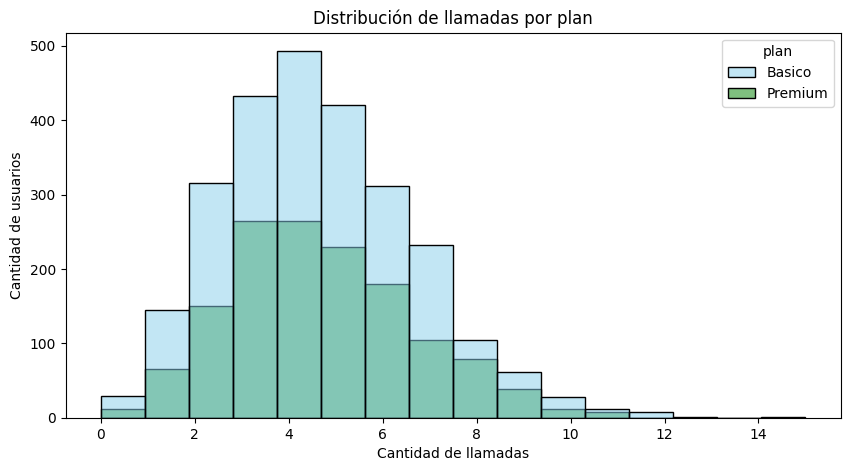

In [57]:
# Histograma para visualizar la cant_llamadas

plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    hue_order=['Basico', 'Premium'],
    bins=16,
    palette=['skyblue', 'green']
)

plt.title('Distribución de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()



💡Insights: 
- Distribución ...
- La distribución de llamadas presenta una concentración principalmente entre 3 y 6 llamadas por usuario, con un promedio de 4.48 y una mediana de 4 llamadas.

Se observa una distribución ligeramente sesgada hacia la derecha, debido a que algunos usuarios presentan consumos superiores a 10 llamadas.

Los planes Básico y Premium muestran patrones visualmente similares. Aunque el plan Básico registra una mayor cantidad de usuarios, esto se relaciona con su mayor participación en la base de clientes (64.88%).

Se recomienda analizar los consumos extremos para determinar si representan comportamientos atípicos y evaluar posibles diferencias entre los segmentos.

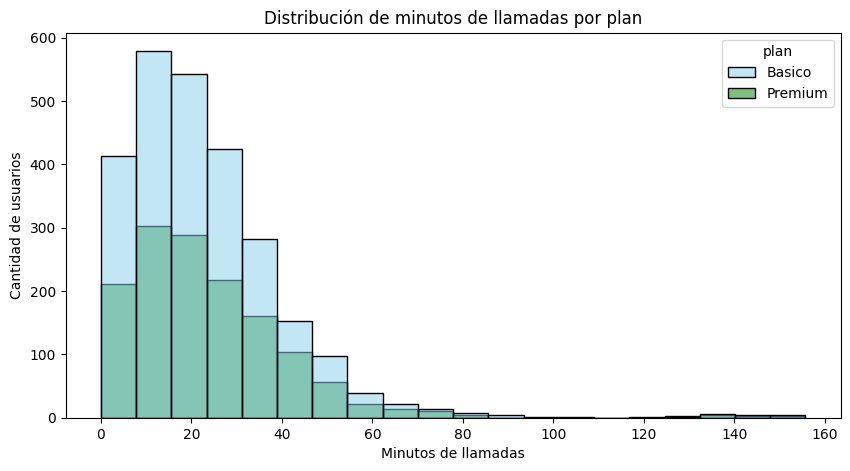

In [58]:
# Histograma para visualizar la cant_minutos_llamada

plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    hue_order=['Basico', 'Premium'],
    bins=20,
    palette=['skyblue', 'green']
)

plt.title('Distribución de minutos de llamadas por plan')
plt.xlabel('Minutos de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()




💡Insights: 
- ...
- La distribución de minutos de llamadas presenta un sesgo positivo (hacia la derecha), con una mayor concentración de usuarios entre aproximadamente 5 y 35 minutos.

El promedio de 23.32 minutos supera la mediana de 19.78 minutos, lo que indica que los consumos elevados influyen en el promedio general.

Ambos planes presentan patrones visualmente similares, aunque el plan Básico concentra una mayor cantidad de usuarios debido a su mayor participación en la base de clientes.

Se identifican consumos extremos superiores a 100 minutos, que requieren un análisis de valores atípicos para determinar si corresponden a comportamientos reales o posibles inconsistencias en los datos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

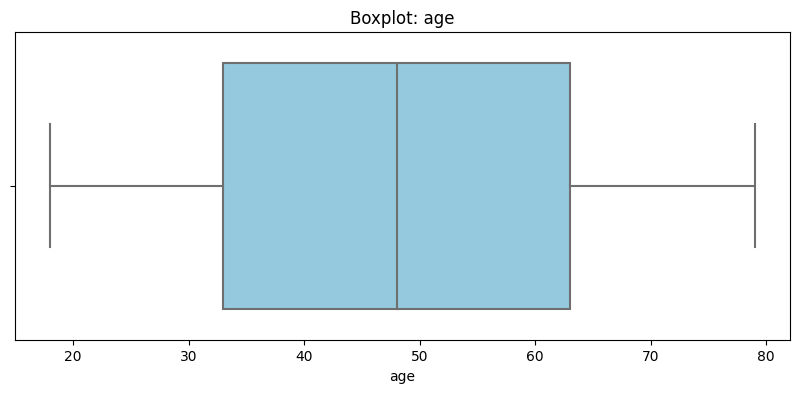

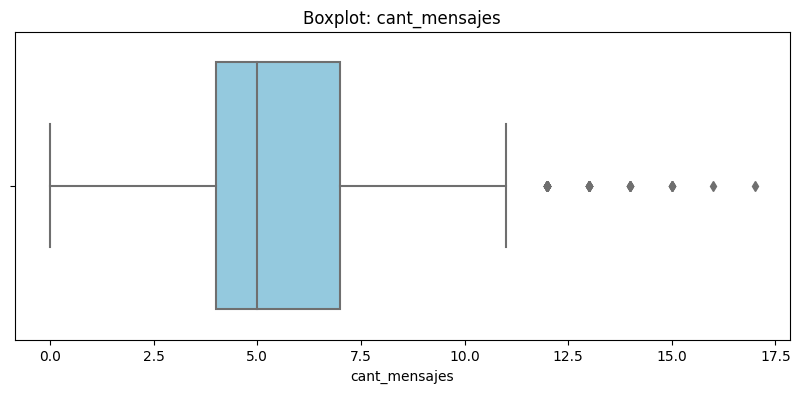

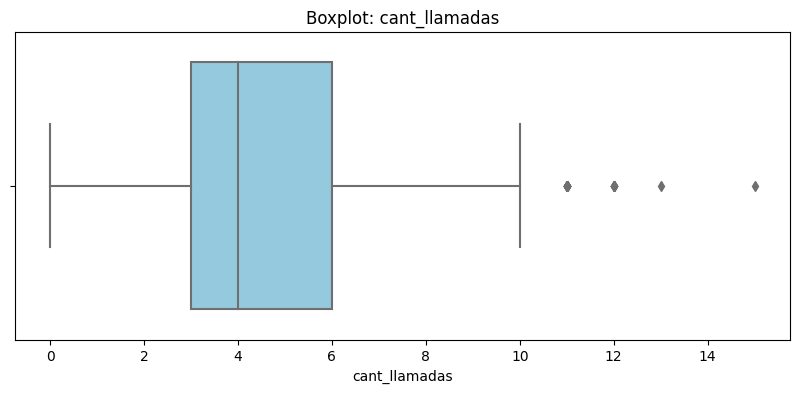

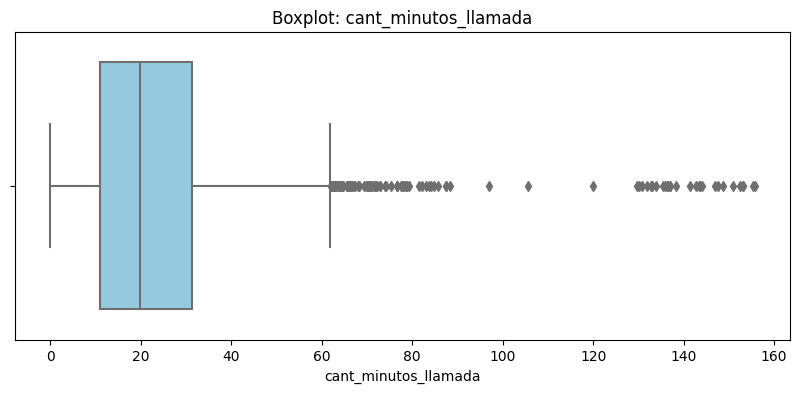

In [59]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(10, 4))

    sns.boxplot(
        data=user_profile,
        x=col,
        color='skyblue'
    )

    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 

Age: No presenta outliers. Las edades se encuentran entre 18 y 79 años, dentro de los límites del boxplot, con una mediana cercana a 48 años.

cant_mensajes: Presenta outliers superiores, aproximadamente entre 12 y 17 mensajes. La mayoría de los usuarios registra entre 4 y 7 mensajes.

cant_llamadas: Presenta outliers superiores, aproximadamente entre 11 y 15 llamadas. La mayoría de los usuarios registra entre 3 y 6 llamadas.

cant_minutos_llamada: Presenta numerosos outliers superiores a aproximadamente 62 minutos, alcanzando un máximo de 155.69 minutos. Esto confirma una distribución sesgada hacia la derecha, con algunos usuarios que presentan consumos significativamente elevados.

In [60]:
# Calcular límites con el método IQR

columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_superior = Q3 + 1.5 * IQR

    outliers = user_profile[
        user_profile[col] > limite_superior
    ]

    print(f'Columna: {col}')
    print(f'Q1: {Q1:.2f}')
    print(f'Q3: {Q3:.2f}')
    print(f'IQR: {IQR:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Cantidad de outliers: {len(outliers)}')
    print('----------------------------')


Columna: cant_mensajes
Q1: 4.00
Q3: 7.00
IQR: 3.00
Límite superior: 11.50
Cantidad de outliers: 46
----------------------------
Columna: cant_llamadas
Q1: 3.00
Q3: 6.00
IQR: 3.00
Límite superior: 10.50
Cantidad de outliers: 30
----------------------------
Columna: cant_minutos_llamada
Q1: 11.12
Q3: 31.41
IQR: 20.30
Límite superior: 61.86
Cantidad de outliers: 109
----------------------------


In [61]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
  cant_mensajes: Se identificaron 46 outliers (1.15%), con valores superiores a 11.5 mensajes y un máximo de 17. Se recomienda mantenerlos, ya que representan una proporción pequeña y podrían corresponder a usuarios con mayor actividad de mensajería, sin evidencia suficiente de errores.
  
- cant_llamadas: mantener o no outliers, porqué?
  cant_llamadas: Se encontraron 30 outliers (0.75%), con valores superiores a 10.5 llamadas y un máximo de 15. Se recomienda mantenerlos, porque podrían reflejar comportamientos legítimos de clientes con mayor frecuencia de llamadas y aportar información útil para la segmentación.

  
- cant_minutos_llamada: mantener o no outliers, porqué?
  cant_minutos_llamada: Se identificaron 109 outliers (2.73%), con valores superiores a 61.86 minutos y un máximo de 155.69. Se recomienda mantenerlos provisionalmente, pero revisar los consumos más extremos para descartar errores de registro. Estos clientes podrían representar un segmento de alto consumo con necesidades comerciales específicas.


Conclusión general: Los outliers representan una proporción minoritaria de los registros analizados. Se conservarán para evitar la pérdida de información sobre usuarios de alto consumo, aunque será importante validar los valores extremos y considerar su influencia en los análisis estadísticos posteriores

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [62]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) &
    (user_profile['cant_mensajes'] < 5),

    (user_profile['cant_llamadas'] < 10) &
    (user_profile['cant_mensajes'] < 10)
]

categorias = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(
    condiciones,
    categorias,
    default='Alto uso'
)

In [63]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [64]:
# Crear columna grupo_edad
condiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

categorias = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(
    condiciones,
    categorias,
    default='Adulto Mayor'
)


In [65]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

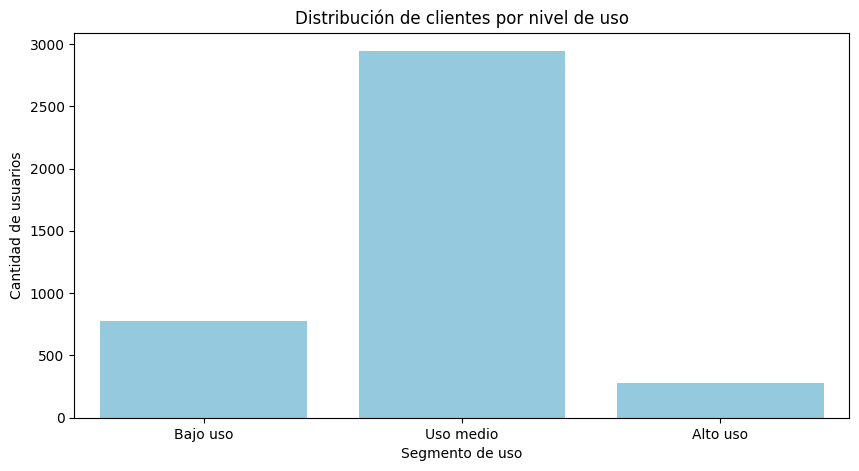

In [66]:
# Visualización de los segmentos por uso

plt.figure(figsize=(10, 5))

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    color='skyblue'
)

plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Segmento de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

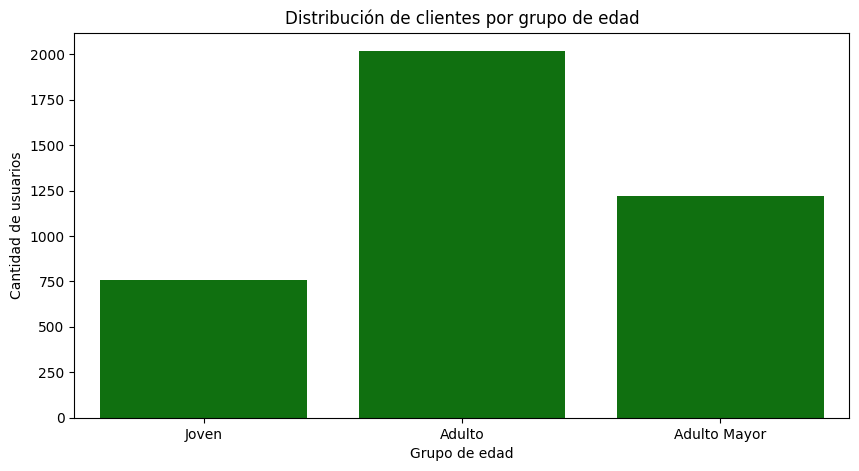

In [67]:
# Visualización de los segmentos por edad
plt.figure(figsize=(10, 5))

sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    color='green'
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 

- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

Durante la exploración inicial se identificaron problemas de calidad en ambos datasets.

En users_latam, la columna city presentó 469 valores nulos (11.725%) y 96 registros adicionales con el valor inválido "?" (2.4%). La columna age contenía valores sentinels de -999, que no representan edades válidas. Además, churn_date registró 3,534 valores nulos (88.35%), posiblemente asociados a clientes que aún permanecen activos.

En usage, se identificaron 22,076 valores nulos en duration (55.19%) y 17,896 en length (44.74%). Se comprobó que estos valores dependen del tipo de actividad, por lo que se conservaron como nulos estructurales.

También se encontraron 40 fechas de registro correspondientes a 2026 (1% de los usuarios), fuera del periodo válido hasta 2024, y 50 fechas faltantes o inválidas en usage (0.125%).

Se aplicaron reglas de limpieza para corregir valores inválidos, reemplazar sentinels y marcar fechas inconsistentes como nulas.


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

Se clasificaron los clientes en tres segmentos de consumo: Bajo uso, Uso medio y Alto uso, considerando la cantidad de llamadas y mensajes realizados.

Los resultados muestran que el segmento de Uso medio concentra la mayor cantidad de clientes, con aproximadamente 3,000 usuarios, seguido de Bajo uso y Alto uso.

Adicionalmente, se establecieron tres grupos de edad:

Joven: menores de 30 años.

Adulto: entre 30 y 59 años.

Adulto Mayor: 60 años o más.

El grupo de adultos es el más numeroso, con aproximadamente 2,000 clientes, seguido de adultos mayores y jóvenes.

Estos resultados permiten identificar la composición de la base de clientes. Sin embargo, para determinar cómo cambia el nivel de consumo según la edad, es necesario cruzar ambas segmentaciones.


- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

El segmento de Uso medio representa una oportunidad comercial importante, debido a que concentra la mayor parte de los clientes. Optimizar los planes dirigidos a este grupo podría beneficiar a una proporción significativa de usuarios.

Por otra parte, el segmento de Alto uso podría representar una oportunidad de crecimiento mediante planes con mayores beneficios de llamadas y mensajes.

Los usuarios de Bajo uso también son relevantes, ya que podrían beneficiarse de planes económicos y flexibles que favorezcan su permanencia.

Estas oportunidades deben validarse con información de ingresos, rentabilidad y cancelaciones antes de determinar qué segmento genera mayor valor económico.


- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

Mediante el método IQR se identificaron valores atípicos en tres variables:

cant_mensajes: 46 usuarios (1.15%), con un máximo de 17 mensajes y un límite superior de 11.50.

cant_llamadas: 30 usuarios (0.75%), con un máximo de 15 llamadas y un límite superior de 10.50.

cant_minutos_llamada: 109 usuarios (2.73%), con un máximo de 155.69 minutos y un límite superior de 61.86.

La mayor cantidad de valores atípicos se presentó en los minutos acumulados de llamadas, lo que indica que algunos usuarios tienen un consumo considerablemente superior al habitual.

Se decidió conservar estos registros inicialmente, ya que podrían representar comportamientos reales y oportunidades comerciales. No existen evidencias suficientes para clasificarlos automáticamente como errores o fraude.


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

A partir de los resultados obtenidos, se proponen las siguientes recomendaciones:

Optimizar los planes de consumo medio: desarrollar ofertas equilibradas de llamadas y mensajes, considerando que este segmento representa la mayor proporción de clientes.

Evaluar planes para usuarios de alto consumo: ofrecer paquetes ampliados de minutos y mensajes, sujetos a una evaluación de rentabilidad.

Crear alternativas para usuarios de bajo consumo: diseñar planes económicos y flexibles que se adapten mejor a sus necesidades.

Personalizar las estrategias comerciales: combinar información de edad, consumo y plan contratado para identificar necesidades diferenciadas.

Monitorear comportamientos atípicos: implementar controles periódicos que permitan identificar consumos extremos, posibles errores de registro y oportunidades de mejora.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

En users_latam se identificaron 469 valores nulos en city (11.73%), 96 registros con "?" (2.4%), edades inválidas (-999) y 40 fechas futuras (1%). Estos problemas requirieron limpieza para garantizar la confiabilidad del análisis.

En usage, las columnas duration y length presentaron 55.19% y 44.74% de valores nulos, respectivamente. Se identificó que estos dependen del tipo de actividad (llamadas o mensajes), por lo que se conservaron como nulos estructurales.


🔍 **Segmentos por Edad**

Adultos (30–59 años): representan el grupo más numeroso, con aproximadamente 2,000 usuarios, constituyendo el principal segmento demográfico.

Adultos mayores (60 años o más) y jóvenes (menores de 30): representan grupos más pequeños, con aproximadamente 1,200 y 750 usuarios, respectivamente, que podrían tener necesidades comerciales diferenciadas.


📊 **Segmentos por Nivel de Uso**

Uso medio: es el segmento predominante, con aproximadamente 3,000 usuarios. Esto sugiere que la mayoría de los clientes mantiene un consumo moderado de llamadas y mensajes.

Bajo y alto uso: aproximadamente 800 usuarios presentan bajo consumo y menos de 300 se encuentran en alto consumo. El método IQR también identificó 46 valores atípicos en mensajes, 30 en llamadas y 109 en minutos acumulados.


➡️ Esto sugiere que ...

ConnectaTel cuenta con una base de clientes concentrada principalmente en adultos y usuarios de consumo medio. Existe una oportunidad para optimizar los planes dirigidos a este segmento mayoritario y evaluar ofertas especializadas para usuarios con necesidades de consumo superiores o inferiores al promedio.

Los valores atípicos podrían representar patrones reales de consumo elevado, por lo que conviene conservarlos y analizarlos antes de tomar decisiones comerciales.

💡 **Recomendaciones**

Optimización y personalización de planes: fortalecer los planes de consumo medio, evaluar paquetes ampliados para usuarios intensivos y ofrecer alternativas flexibles para clientes de bajo consumo.

Mejorar la toma de decisiones: implementar monitoreo de consumos atípicos, fortalecer la calidad de los datos y cruzar las variables de edad, consumo y tipo de plan para identificar oportunidades comerciales y mejorar la retención de clientes.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`